Starter med å sette opp. importere og definere

extra

In [ ]:
%pip

Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path
import os
from sklearn.model_selection import train_test_split


In [2]:
import sys; sys.path.append("..")
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import v2
#from torchvision.io import decode_image, ImageReadMode
from PIL import Image  # torchvision fra AMD (ROCm) mangler JPEG-støtte, så bilder leses med PIL

DATA

In [3]:
NB_DIR = Path.cwd()       # Set NB_DIR to be the current working directory
DATA = NB_DIR.parent/'data' 


In [4]:
FILE = DATA / 'flowers'

In [5]:
LABEL = DATA / 'labels.csv'

In [6]:
# klasser og antall
from collections import Counter

root = FILE  # change to your unzipped folder name
for dirpath, dirs, files in os.walk(root):
    imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if imgs:
        print(f"{os.path.basename(dirpath)}: {len(imgs)} images")

astilbe: 737 images
bellflower: 873 images
black_eyed_susan: 1000 images
calendula: 978 images
california_poppy: 1022 images
carnation: 923 images
common_daisy: 980 images
coreopsis: 1047 images
daffodil: 970 images
dandelion: 1052 images
iris: 1054 images
lavender: 500 images
lotus: 500 images
magnolia: 1048 images
orchid: 489 images
rose: 999 images
sunflower: 1027 images
tulip: 1048 images
water_lily: 982 images


Lek

In [7]:
#test
x = torch.rand(5, 3)
print(x)


tensor([[0.6487, 0.1879, 0.1866],
        [0.5529, 0.5807, 0.4247],
        [0.9849, 0.8078, 0.6374],
        [0.0063, 0.9489, 0.6902],
        [0.2552, 0.7514, 0.0100]])


INIT data


In [8]:
#lage labels / definerer klassene og lage splits.

classes = sorted(d.name for d in FILE.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(classes)}

rows = []
for c in classes:
    for f in (FILE / c).iterdir():
        if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
            rows.append({"path": f"{c}/{f.name}", "label": class_to_idx[c]})
df = pd.DataFrame(rows)

# 70/15/15, stratifisert
train, tmp = train_test_split(df, test_size=0.3, stratify=df.label, random_state=42)
val, test  = train_test_split(tmp, test_size=0.5, stratify=tmp.label, random_state=42)
df["split"] = "train"
df.loc[val.index, "split"] = "val"
df.loc[test.index, "split"] = "test"

df.to_csv(DATA / "labels.csv", index=False)
print(df.split.value_counts(), "\n", classes)

split
train    12060
test      2585
val       2584
Name: count, dtype: int64 
 ['astilbe', 'bellflower', 'black_eyed_susan', 'calendula', 'california_poppy', 'carnation', 'common_daisy', 'coreopsis', 'daffodil', 'dandelion', 'iris', 'lavender', 'lotus', 'magnolia', 'orchid', 'rose', 'sunflower', 'tulip', 'water_lily']


In [9]:
# INIT data
# CustomImageDataset ligger i src/data.py (leser bilder med PIL)
from src.data import CustomImageDataset


In [10]:
# augmentering. endring av input for å motvirke overfitting
# train_tf (RandomResizedCrop + flip) og eval_tf (Resize 256 + CenterCrop 224) ligger i src/data.py
from src.data import train_tf, eval_tf, MEAN as mean, STD as std


In [11]:
training_data = CustomImageDataset(LABEL, FILE, "train", train_tf)
val_data      = CustomImageDataset(LABEL, FILE, "val",   eval_tf)
test_data     = CustomImageDataset(LABEL, FILE, "test",  eval_tf)

In [12]:
# DATA loader

batch_size = 64

# Create data loaders.
loader_kw = dict(num_workers=8, persistent_workers=True, pin_memory=True)
train_dataloader = DataLoader(training_data, batch_size=batch_size, shuffle=True, **loader_kw)
val_dataloader   = DataLoader(val_data,      batch_size=batch_size, **loader_kw)
test_dataloader  = DataLoader(test_data,     batch_size=batch_size, **loader_kw)

X, y = next(iter(train_dataloader))
print(X.shape, X.dtype, y[:8])  # torch.Size([32, 3, 224, 224]) torch.float32

torch.Size([64, 3, 224, 224]) torch.float32 tensor([ 6,  9, 18, 18,  6,  6,  2, 16])


Feature batch shape: torch.Size([64, 3, 224, 224])
Labels batch shape: torch.Size([64])


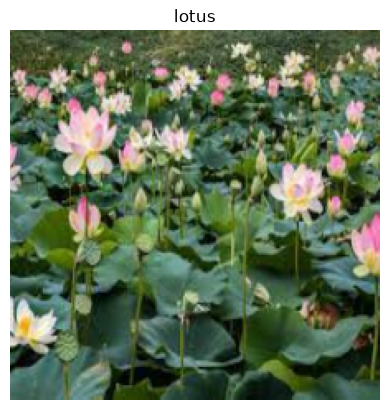

Label: 12 (lotus)


In [13]:
#display

# Display image and label.
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")

img = train_features[0]                                            # [3, 224, 224]
img = img * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)  # angre Normalize
img = img.permute(1, 2, 0).clamp(0, 1)                             # -> [224, 224, 3]
label = train_labels[0].item()

plt.imshow(img)
plt.title(classes[label])
plt.axis("off")
plt.show()
print(f"Label: {label} ({classes[label]})")



In [14]:
#???
import torch.nn.functional as F
from torchvision import datasets
from torchvision.transforms import v2

Chapter 3 Modellen

In [15]:
import os
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [16]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [17]:
from src.utils import get_device

device = get_device()
print(device, torch.cuda.get_device_name(device))  # forventet: AMD Radeon RX 9070 XT

cuda:0 AMD Radeon RX 9070 XT


In [19]:
# FlowerNet ligger i src/model.py
from src.model import FlowerNet

model = FlowerNet(len(classes)).to(device)

X, y = next(iter(train_dataloader))
print(model(X.to(device)).shape)  # torch.Size([64, 19])

c:\Users\anton\Desktop\ML\Blomst\BloMLster\.venv-rocm\Lib\site-packages\torch\backends\cudnn\__init__.py:177: UserWarning: cuDNN Benchmark limit is not supported in MIOpen and will have no effect. (Triggered internally at B:/src/pytorch/torch/csrc/cuda/Module.cpp:2178.)
  torch._C._cuda_set_cudnn_benchmark_limit(_benchmark_limit)


torch.Size([64, 19])


In [20]:
model = FlowerNet(len(classes)).to(device)
print(model)

FlowerNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride

In [21]:
from src.config import MODELS_DIR
MODELS_DIR.mkdir(exist_ok=True)

model = FlowerNet(len(classes)).to(device)        # ny, utrent modell
loss_fn = nn.CrossEntropyLoss()

epochs = 50
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, epochs=epochs, steps_per_epoch=len(train_dataloader))

def train(dataloader, model, loss_fn, optimizer):
    model.train()
    total_loss, correct = 0, 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            pred = model(X)
            loss = loss_fn(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * len(X)
        correct += (pred.argmax(1) == y).sum().item()
    n = len(dataloader.dataset)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(dataloader, model, loss_fn):
    model.eval()
    total_loss, correct = 0, 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            pred = model(X)
            total_loss += loss_fn(pred, y).item() * len(X)
        correct += (pred.argmax(1) == y).sum().item()
    n = len(dataloader.dataset)
    return total_loss / n, correct / n


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc = -1  # første epoke lagres alltid
for epoch in range(epochs):
    train_loss, train_acc = train(train_dataloader, model, loss_fn, optimizer)
    val_loss, val_acc = evaluate(val_dataloader, model, loss_fn)
    for k, v in zip(history, (train_loss, val_loss, train_acc, val_acc)):
        history[k].append(v)
    print(f"Epoch {epoch+1:2d}: train loss {train_loss:.3f} acc {train_acc:.1%} | val loss {val_loss:.3f} acc {val_acc:.1%}")

    # lagre beste epoke på valideringssettet (ikke siste)
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save({
            "state_dict": model.state_dict(),
            "classes": classes,
            "mean": mean, "std": std,
            "img_size": 224,
            "epoch": epoch + 1,
            "val_acc": val_acc,
            "history": history,
        }, MODELS_DIR / "flowernet.pt")
        print("  -> lagret som beste modell")


Epoch  1: train loss 1.875 acc 40.3% | val loss 1.584 acc 48.6%
  -> lagret som beste modell
Epoch  2: train loss 1.490 acc 52.4% | val loss 1.835 acc 47.3%
Epoch  3: train loss 1.339 acc 57.3% | val loss 1.337 acc 56.3%
  -> lagret som beste modell
Epoch  4: train loss 1.233 acc 60.7% | val loss 1.404 acc 56.7%
  -> lagret som beste modell
Epoch  5: train loss 1.151 acc 63.4% | val loss 1.476 acc 55.4%
Epoch  6: train loss 1.025 acc 66.9% | val loss 1.117 acc 65.7%
  -> lagret som beste modell
Epoch  7: train loss 0.982 acc 68.5% | val loss 1.456 acc 59.2%
Epoch  8: train loss 0.928 acc 70.7% | val loss 1.155 acc 65.9%
  -> lagret som beste modell
Epoch  9: train loss 0.835 acc 73.1% | val loss 1.272 acc 61.9%
Epoch 10: train loss 0.779 acc 75.2% | val loss 1.235 acc 66.6%
  -> lagret som beste modell
Epoch 11: train loss 0.717 acc 77.5% | val loss 1.450 acc 61.4%
Epoch 12: train loss 0.676 acc 78.5% | val loss 1.152 acc 67.3%
  -> lagret som beste modell
Epoch 13: train loss 0.627 ac

In [22]:
# last beste epoke før test, siden modellen i minnet er fra siste epoke
ckpt = torch.load(MODELS_DIR / "flowernet.pt", map_location=device)
model.load_state_dict(ckpt["state_dict"])

test_loss, test_acc = evaluate(test_dataloader, model, loss_fn)
print(f"Beste epoke: {ckpt['epoch']} (val acc {ckpt['val_acc']:.1%}) | Test acc: {test_acc:.1%}")


Beste epoke: 42 (val acc 91.8%) | Test acc: 92.3%


In [23]:
# legg testresultat og hele treningshistorikken til i den lagrede modellen
ckpt["test_acc"] = test_acc
ckpt["history"] = history
torch.save(ckpt, MODELS_DIR / "flowernet.pt")

In [24]:
X = torch.rand(1, 28, 28, device=device)
logits = model(X)
pred_probab = nn.Softmax(dim=1)(logits)
y_pred = pred_probab.argmax(1)
print(f"Predicted class: {y_pred}")

RuntimeError: Given groups=1, weight of size [32, 3, 3, 3], expected input[1, 1, 28, 28] to have 3 channels, but got 1 channels instead

In [21]:
input_image = torch.rand(3,28,28)
print(input_image.size())

torch.Size([3, 28, 28])


In [23]:
flatten = nn.Flatten()
flat_image = flatten(input_image)
print(flat_image.size())

torch.Size([3, 784])


In [24]:
layer1 = nn.Linear(in_features=28*28, out_features=20)
hidden1 = layer1(flat_image)
print(hidden1.size())

torch.Size([3, 20])


In [25]:
seq_modules = nn.Sequential(
    flatten,
    layer1,
    nn.ReLU(),
    nn.Linear(20, 10)
)
input_image = torch.rand(3,28,28)
logits = seq_modules(input_image)

In [26]:
softmax = nn.Softmax(dim=1)
pred_probab = softmax(logits)

In [27]:
print(f"Model structure: {model}\n\n")

for name, param in model.named_parameters():
    print(f"Layer: {name} | Size: {param.size()} | Values : {param[:2]} \n")

Model structure: NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


Layer: linear_relu_stack.0.weight | Size: torch.Size([512, 784]) | Values : tensor([[-0.0044,  0.0177,  0.0327,  ..., -0.0007, -0.0350,  0.0196],
        [ 0.0280, -0.0315, -0.0207,  ...,  0.0197, -0.0023, -0.0174]],
       device='cuda:0', grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.0.bias | Size: torch.Size([512]) | Values : tensor([ 0.0004, -0.0304], device='cuda:0', grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.2.weight | Size: torch.Size([512, 512]) | Values : tensor([[-0.0171,  0.0167, -0.0365,  ...,  0.0021,  0.0304,  0.0144],
        [-0.0206, -0.0343, -0.0225,  ...,  0.0286,  0.0340,  0.0003]],
       device='cuda:0', grad_fn=<Sl

Automatic Diff

In [28]:
x = torch.ones(5)  # input tensor
y = torch.zeros(3)  # expected output
w = torch.randn(5, 3, requires_grad=True)
b = torch.randn(3, requires_grad=True)
z = torch.matmul(x, w)+b
loss = torch.nn.functional.binary_cross_entropy_with_logits(z, y)

In [29]:
print(f"Gradient function for z = {z.grad_fn}")
print(f"Gradient function for loss = {loss.grad_fn}")

Gradient function for z = <AddBackward0 object at 0x00000250D29A9AB0>
Gradient function for loss = <BinaryCrossEntropyWithLogitsBackward0 object at 0x00000250D285D630>


In [30]:
loss.backward()
print(w.grad)
print(b.grad)

tensor([[0.1105, 0.0498, 0.1470],
        [0.1105, 0.0498, 0.1470],
        [0.1105, 0.0498, 0.1470],
        [0.1105, 0.0498, 0.1470],
        [0.1105, 0.0498, 0.1470]])
tensor([0.1105, 0.0498, 0.1470])


In [31]:
z = torch.matmul(x, w)+b
print(z.requires_grad)

with torch.no_grad():
    z = torch.matmul(x, w)+b
print(z.requires_grad)

True
False


In [32]:
z = torch.matmul(x, w)+b
z_det = z.detach()
print(z_det.requires_grad)

False


In [33]:
inp = torch.eye(4, 5, requires_grad=True)
out = (inp+1).pow(2).t()
out.backward(torch.ones_like(out), retain_graph=True)
print(f"First call\n{inp.grad}")
out.backward(torch.ones_like(out), retain_graph=True)
print(f"\nSecond call\n{inp.grad}")
inp.grad.zero_()
out.backward(torch.ones_like(out), retain_graph=True)
print(f"\nCall after zeroing gradients\n{inp.grad}")

First call
tensor([[4., 2., 2., 2., 2.],
        [2., 4., 2., 2., 2.],
        [2., 2., 4., 2., 2.],
        [2., 2., 2., 4., 2.]])

Second call
tensor([[8., 4., 4., 4., 4.],
        [4., 8., 4., 4., 4.],
        [4., 4., 8., 4., 4.],
        [4., 4., 4., 8., 4.]])

Call after zeroing gradients
tensor([[4., 2., 2., 2., 2.],
        [2., 4., 2., 2., 2.],
        [2., 2., 4., 2., 2.],
        [2., 2., 2., 4., 2.]])
